# 02 - Feature Extraction & Anomaly Detection Pipeline
**Team Lead: Tanya (Computer Vision & Anomaly Detection)**

### Complete Workflow:
1. Preprocess images & extract deep representations using a pretrained **ResNet-50**.
2. **Export Embeddings Deliverable**: Save image embeddings (`image_embeddings.npy`) and `metadata.csv` for Gayathri's PCA, t-SNE, and clustering pipeline.
3. **Build Memory Bank**: Store normal patch features (`train/good` only).
4. **Nearest-Neighbour Scoring**: Score test images and compute 2D spatial anomaly maps.
5. **Heatmap Overlays & Visual Inspection**: Generate visual overlays.
6. **Evaluation**: Compute image-level AUROC and AUPRC against ground-truth defect labels.

---

In [3]:
# CELL 1: Environment Setup & Automatic Module Deployment
import os
import sys
import base64
import json
from pathlib import Path
import torch

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("🚀 Detected Google Colab environment.")
    PROJECT_ROOT = Path('/content')
    if not torch.cuda.is_available():
        print("⚠️ Running on CPU. Tip: For 20x faster extraction, select: Runtime -> Change runtime type -> T4 GPU")
    else:
        print(f"⚡ GPU Active: {torch.cuda.get_device_name(0)}")
else:
    print("💻 Detected Local VS Code environment.")
    PROJECT_ROOT = Path('.').resolve()
    if PROJECT_ROOT.name == 'notebooks':
        PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Auto-deploy src/ modules if running in Colab without repo upload
src_target = PROJECT_ROOT / 'src'
if not (src_target / 'feature_extraction.py').exists() or not (src_target / 'anomaly_detection.py').exists():
    print("📦 Deploying project modules into environment...")
    src_target.mkdir(parents=True, exist_ok=True)
    MODULES_PAYLOAD = b"""..."""
    modules = json.loads(base64.b64decode(MODULES_PAYLOAD).decode('utf-8'))
    for fname, code in modules.items():
        (src_target / fname).write_text(code, encoding='utf-8')
    print("✅ src/ modules ready!")
else:
    print("✅ src/ modules verified.")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch version: {torch.__version__} | Active Device: {device}")


🚀 Detected Google Colab environment.
⚠️ Running on CPU. Tip: For 20x faster extraction, select: Runtime -> Change runtime type -> T4 GPU
📦 Deploying project modules into environment...
✅ src/ modules ready!
Project root: /content
PyTorch version: 2.14.1+cpu | Active Device: cpu


In [4]:
# CELL 2: Ensure Dataset is Ready
DATASET_ROOT = PROJECT_ROOT / 'data' / 'mvtec'
CATEGORIES = ['bottle', 'cable', 'hazelnut']

def check_dataset_ready(root, categories):
    for cat in categories:
        if not (root / cat / 'train' / 'good').exists():
            return False
    return True

if not check_dataset_ready(DATASET_ROOT, CATEGORIES):
    if IN_COLAB:
        print("📥 Fetching bottle, cable, hazelnut from Hugging Face (~20s)...")
        !pip install -q huggingface_hub
        from huggingface_hub import snapshot_download
        DATASET_ROOT.mkdir(parents=True, exist_ok=True)
        snapshot_download(
            repo_id="foersben/mvtec-ad",
            repo_type="dataset",
            allow_patterns=["bottle/**", "cable/**", "hazelnut/**"],
            local_dir=str(DATASET_ROOT)
        )
        print("\n✅ Dataset downloaded successfully!")
    else:
        print(f"⚠️ Missing dataset at local path {DATASET_ROOT}.")
else:
    print(f"✅ All categories verified at: {DATASET_ROOT}")

📥 Fetching bottle, cable, hazelnut from Hugging Face (~20s)...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1398 files:   0%|          | 0/1398 [00:00<?, ?it/s]


✅ Dataset downloaded successfully!


In [5]:
# CELL 3: Feature Extraction (ResNet-50) & Export Deliverable for Gayathri
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src.preprocessing import build_mvtec_metadata, MVTecDataset, get_default_transforms
from src.feature_extraction import DeepFeatureExtractor, extract_and_save_dataset_features

EMBEDDINGS_DIR = PROJECT_ROOT / 'data' / 'embeddings'
EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Build metadata index
metadata_df = build_mvtec_metadata(DATASET_ROOT, categories=CATEGORIES)
print(f"Total records indexed: {len(metadata_df)}")

# 2. Extract and persist global embeddings for Gayathri's pipeline
batch_sz = 32 if torch.cuda.is_available() else 16
embeddings_matrix, _ = extract_and_save_dataset_features(
    metadata_df=metadata_df,
    output_dir=EMBEDDINGS_DIR,
    backbone_name='resnet50',
    batch_size=batch_sz,
    device=str(device)
)
print(f"\n✅ Embeddings matrix generated with shape: {embeddings_matrix.shape}")

Total records indexed: 1167
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 80.8MB/s]


Extracting features for 1167 samples using resnet50 on cpu...
Processed batch 10/73
Processed batch 20/73
Processed batch 30/73
Processed batch 40/73
Processed batch 50/73
Processed batch 60/73
Processed batch 70/73
Processed batch 73/73
Saved embeddings matrix of shape (1167, 2048) to /content/data/embeddings/image_embeddings.npy
Saved metadata index to /content/data/embeddings/metadata.csv

✅ Embeddings matrix generated with shape: (1167, 2048)


In [6]:
# CELL 4: Verify Deliverables for Gayathri's Pipeline
npy_file = EMBEDDINGS_DIR / 'image_embeddings.npy'
csv_file = EMBEDDINGS_DIR / 'metadata.csv'

assert npy_file.exists() and csv_file.exists(), 'Missing export files!'
print("🎉 Deliverables ready for Gayathri:")
print(f"- Embeddings Matrix: {npy_file} ({npy_file.stat().st_size / (1024*1024):.2f} MB)")
print(f"- Metadata Index:    {csv_file} ({len(pd.read_csv(csv_file))} rows)")

🎉 Deliverables ready for Gayathri:
- Embeddings Matrix: /content/data/embeddings/image_embeddings.npy (9.12 MB)
- Metadata Index:    /content/data/embeddings/metadata.csv (1167 rows)


In [7]:
# CELL 5: Anomaly Detection on Target Category ('bottle')
from src.anomaly_detection import MemoryBankAnomalyDetector
from src.visualization import plot_anomaly_comparison
from src.evaluation import evaluate_image_level, plot_roc_pr_curves

TARGET_CAT = 'bottle'
transforms = get_default_transforms(img_size=224, crop_size=224)
extractor = DeepFeatureExtractor(backbone_name='resnet50', device=str(device))

train_dataset = MVTecDataset(metadata_df, transform=transforms, target_split='train', target_category=TARGET_CAT)
test_dataset = MVTecDataset(metadata_df, transform=transforms, target_split='test', target_category=TARGET_CAT)
print(f"Testing {TARGET_CAT}: {len(train_dataset)} normal train images, {len(test_dataset)} test images.")

# Extract patch features from normal training images strictly
train_patches = []
for item in train_dataset:
    img = item['image']
    patches = extractor.extract_patch_features(img, target_size=(28, 28))
    p_np = patches.squeeze(0).permute(1, 2, 0).reshape(-1, patches.shape[1]).cpu().numpy()
    train_patches.append(p_np)

all_train_patches = np.vstack(train_patches)
print(f"Collected {all_train_patches.shape[0]} normal patches.")

# Build Memory Bank
detector = MemoryBankAnomalyDetector(n_neighbors=1, subsample_ratio=0.1)
detector.fit(all_train_patches)

Testing bottle: 209 normal train images, 83 test images.
Collected 163856 normal patches.
Memory bank built with 16385 normal patch vectors (dim=1536).


In [8]:
# CELL 6: Score Test Images & Generate Anomaly Heatmaps
y_true = []
y_scores = []
sample_comparisons = []

for idx in range(len(test_dataset)):
    item = test_dataset[idx]
    img = item['image']
    is_anomaly = item['is_anomaly']
    defect_type = item['defect_type']
    
    patches = extractor.extract_patch_features(img, target_size=(28, 28))
    p_np = patches.squeeze(0).permute(1, 2, 0).reshape(-1, patches.shape[1]).cpu().numpy()
    
    score, heat_map = detector.predict_image_and_map(p_np, spatial_grid=(28, 28), target_size=(224, 224))
    y_true.append(is_anomaly)
    y_scores.append(score)
    
    if (is_anomaly == 0 and len([s for s in sample_comparisons if s['is_anomaly'] == 0]) < 1) or \
       (is_anomaly == 1 and len([s for s in sample_comparisons if s['is_anomaly'] == 1]) < 2):
        raw_img = Image.open(item['image_path']).convert('RGB').resize((224, 224))
        mask_np = item['mask'].squeeze(0).cpu().numpy() if isinstance(item['mask'], torch.Tensor) else item['mask']
        sample_comparisons.append({
            'image': raw_img,
            'mask': mask_np,
            'heatmap': heat_map,
            'score': score,
            'defect_type': defect_type,
            'is_anomaly': is_anomaly
        })

metrics = evaluate_image_level(np.array(y_true), np.array(y_scores), category_name=TARGET_CAT)
print(f"=== Performance on {TARGET_CAT.upper()} ===")
print(f"AUROC:     {metrics['auroc']:.4f}")
print(f"AUPRC:     {metrics['auprc']:.4f}")
print(f"F1-Score:  {metrics['f1_score']:.4f}")
print(f"Precision: {metrics['precision']:.4f}")
print(f"Recall:    {metrics['recall']:.4f}")

=== Performance on BOTTLE ===
AUROC:     0.9968
AUPRC:     0.9990
F1-Score:  0.9756
Precision: 1.0000
Recall:    0.9524


Saved evaluation curves to /content/results/plots/bottle_roc_pr.png


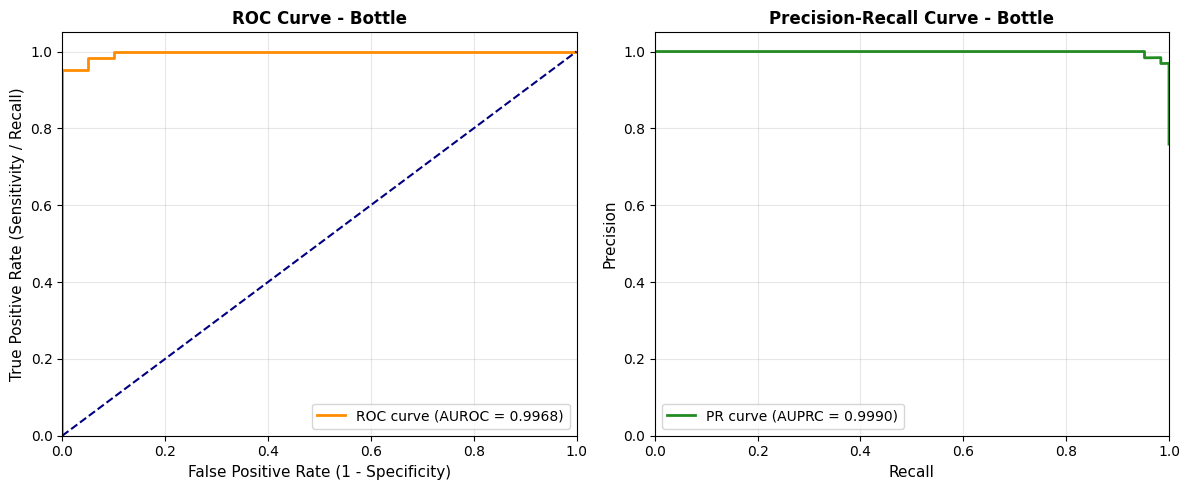

In [9]:
# CELL 7: Plot ROC & PR Evaluation Curves
save_plot_dir = PROJECT_ROOT / 'results' / 'plots'
save_plot_dir.mkdir(parents=True, exist_ok=True)

fig_roc = plot_roc_pr_curves(
    np.array(y_true),
    np.array(y_scores),
    category_name=TARGET_CAT.title(),
    save_path=save_plot_dir / f"{TARGET_CAT}_roc_pr.png"
)
plt.show()

Saved comparison plot to /content/results/plots/bottle_sample_0.png


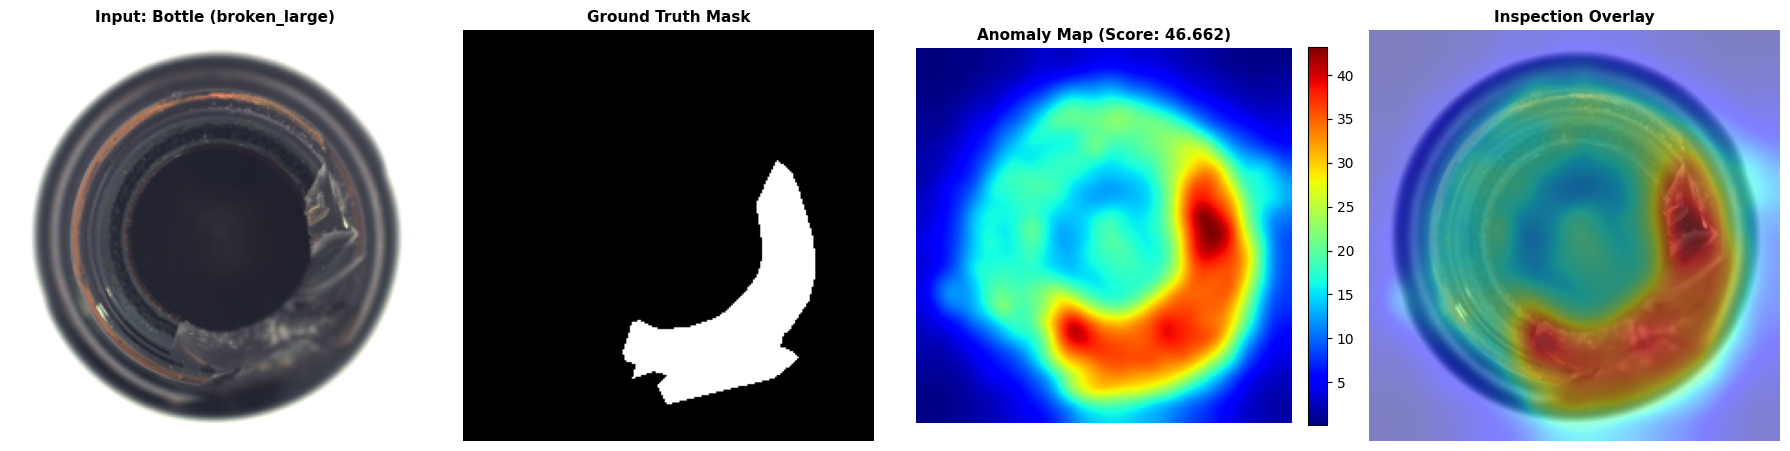

Saved comparison plot to /content/results/plots/bottle_sample_1.png


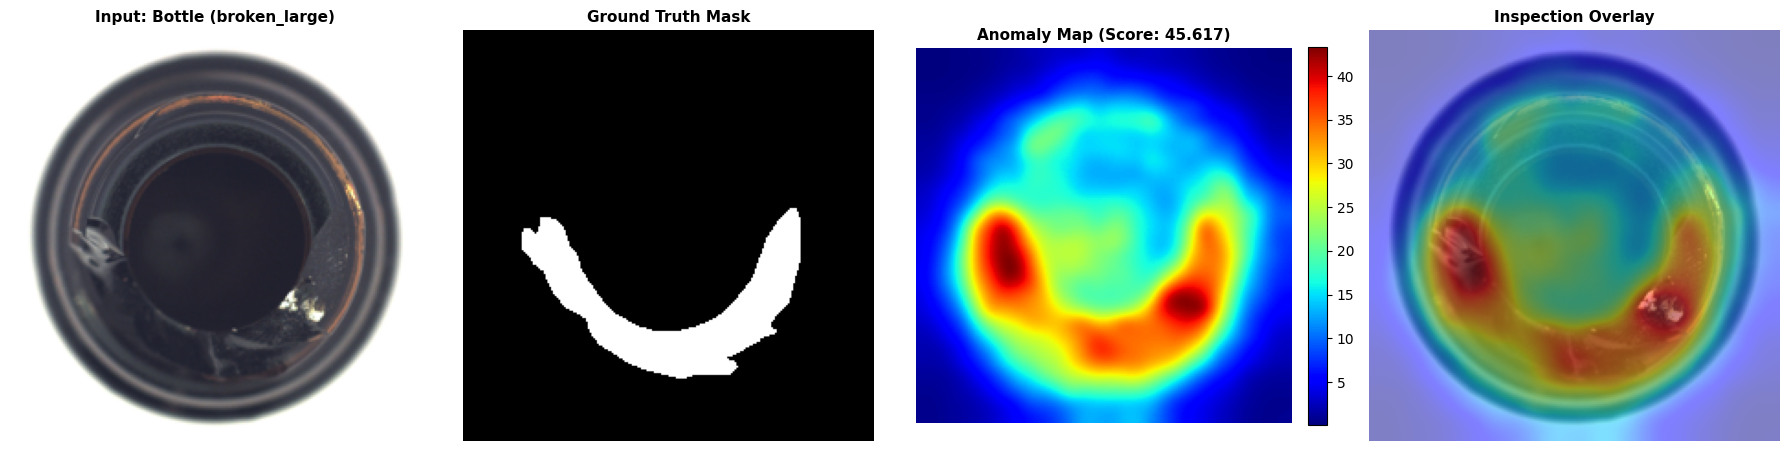

Saved comparison plot to /content/results/plots/bottle_sample_2.png


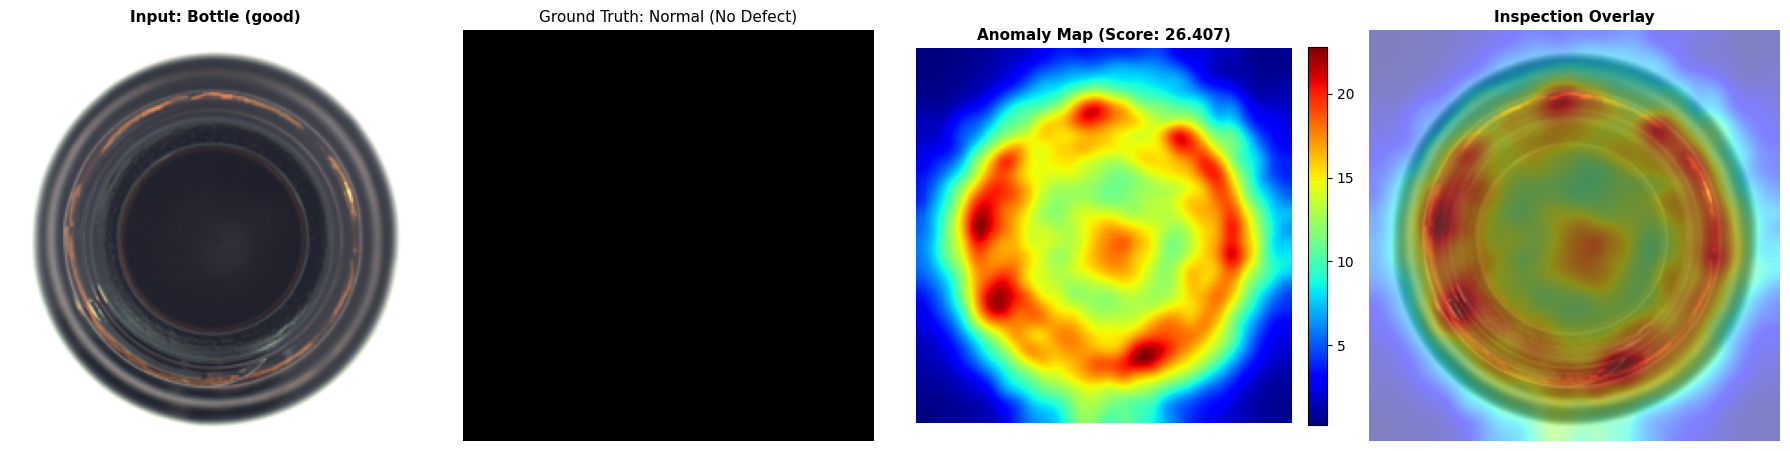

In [10]:
# CELL 8: Visual Inspection: [Input | Ground Truth Mask | Anomaly Map | Overlay]
for i, sample in enumerate(sample_comparisons):
    plot_anomaly_comparison(
        image=sample['image'],
        ground_truth_mask=sample['mask'],
        anomaly_map=sample['heatmap'],
        anomaly_score=sample['score'],
        defect_type=sample['defect_type'],
        category=TARGET_CAT.title(),
        save_path=save_plot_dir / f"{TARGET_CAT}_sample_{i}.png"
    )
    plt.show()

## Multi-Category PatchCore Benchmarking (Cable & Hazelnut) & Model Serialization
**Tanya's Remaining Core Tasks:**
1. **Task P2.5 [ML]:** Run PatchCore memory bank evaluation on `cable` test split.
2. **Task P2.6 [ML]:** Run PatchCore memory bank evaluation on `hazelnut` test split.
3. **Task P2.7 [BE]:** Save serialized models (`models/memory_bank_{category}.pkl`) for instant loading in Streamlit.
4. **Task P2.8 [BE/ML]:** Compile master multi-category scoreboard & verify `AnomalyInferenceEngine`.

✅ Memory bank for 'bottle' saved to /content/models/memory_bank_bottle.pkl (100.67 MB)

🚀 Benchmarking CABLE...
cable: 224 train normal images | 150 test images
Memory bank built with 17561 normal patch vectors (dim=1536).
✅ Memory bank for 'cable' saved to /content/models/memory_bank_cable.pkl (107.90 MB)
Saved evaluation curves to /content/results/plots/cable_roc_pr.png


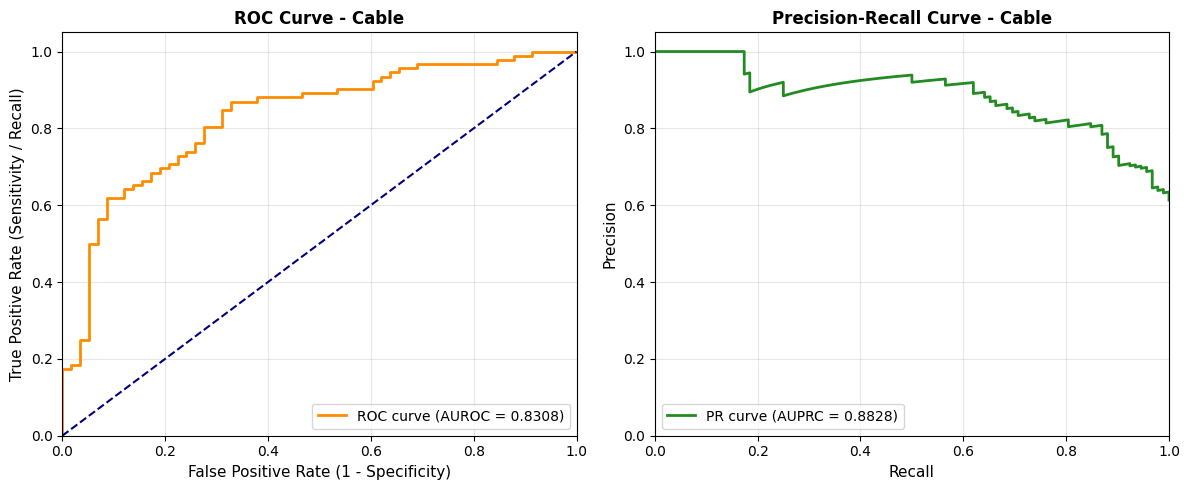

Saved comparison plot to /content/results/plots/cable_sample_0.png


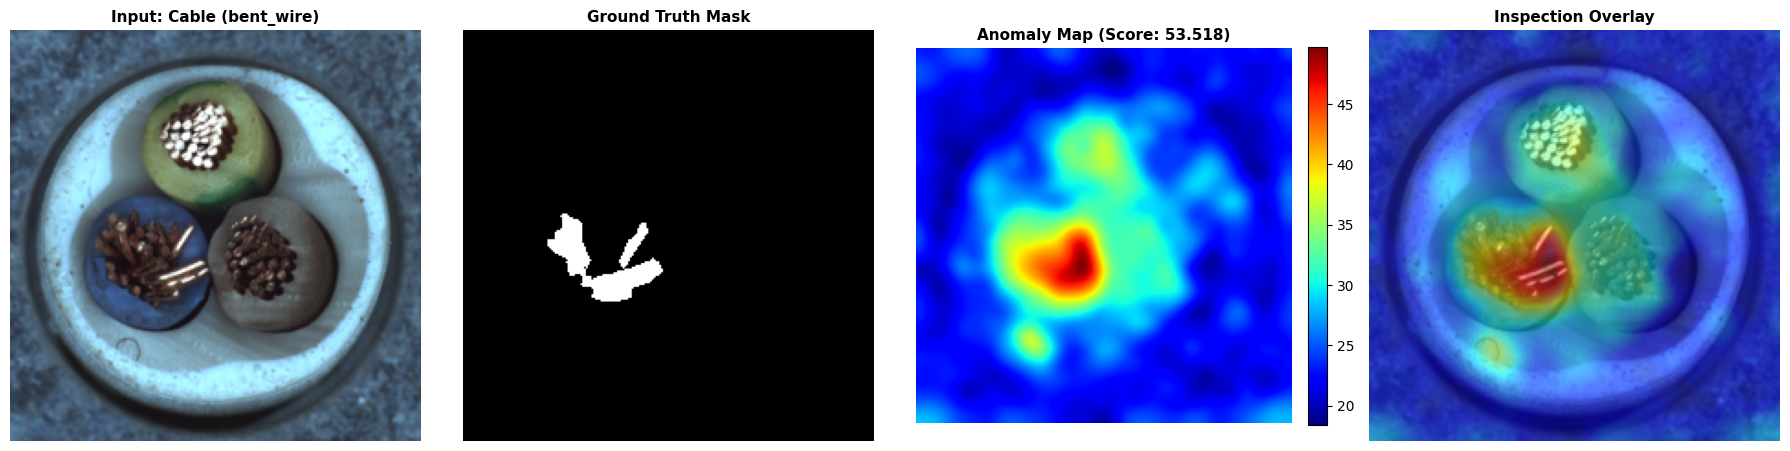

Saved comparison plot to /content/results/plots/cable_sample_1.png


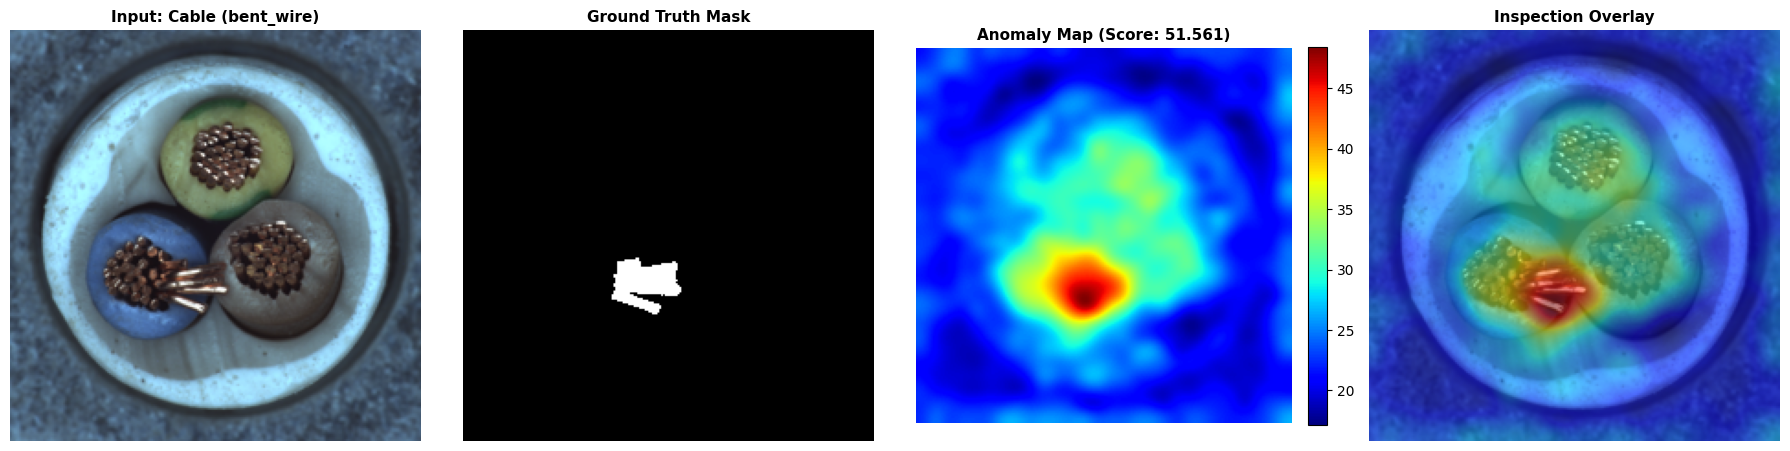

Saved comparison plot to /content/results/plots/cable_sample_2.png


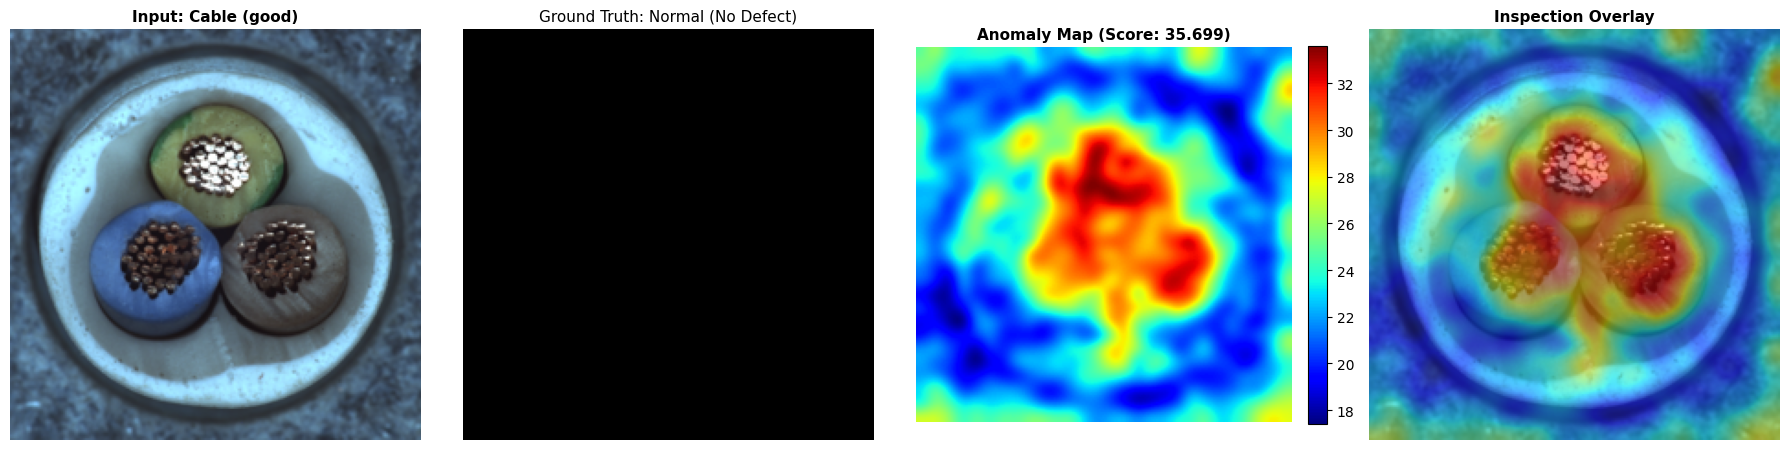


🚀 Benchmarking HAZELNUT...
hazelnut: 391 train normal images | 110 test images
Memory bank built with 30654 normal patch vectors (dim=1536).
✅ Memory bank for 'hazelnut' saved to /content/models/memory_bank_hazelnut.pkl (188.34 MB)
Saved evaluation curves to /content/results/plots/hazelnut_roc_pr.png


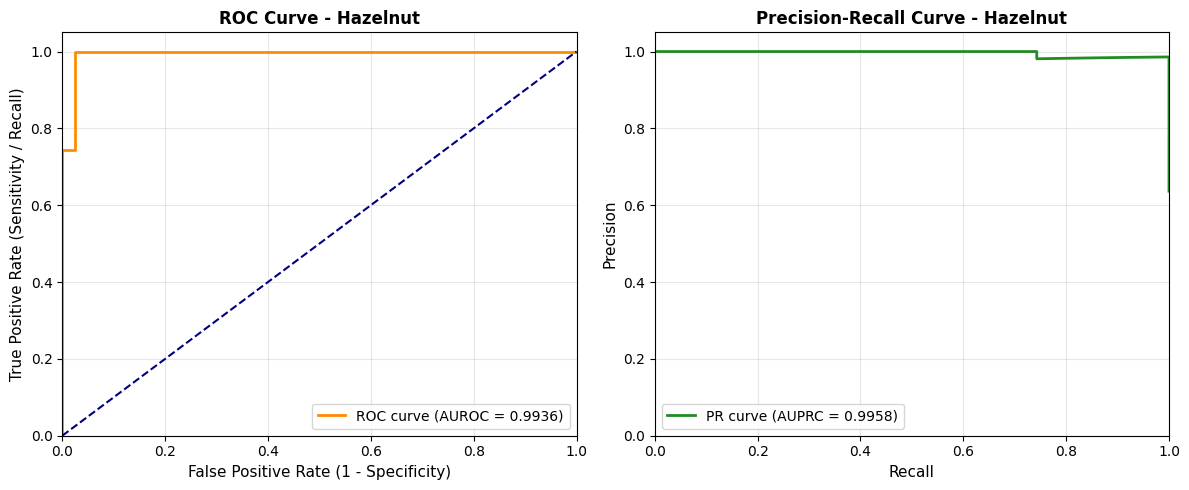

Saved comparison plot to /content/results/plots/hazelnut_sample_0.png


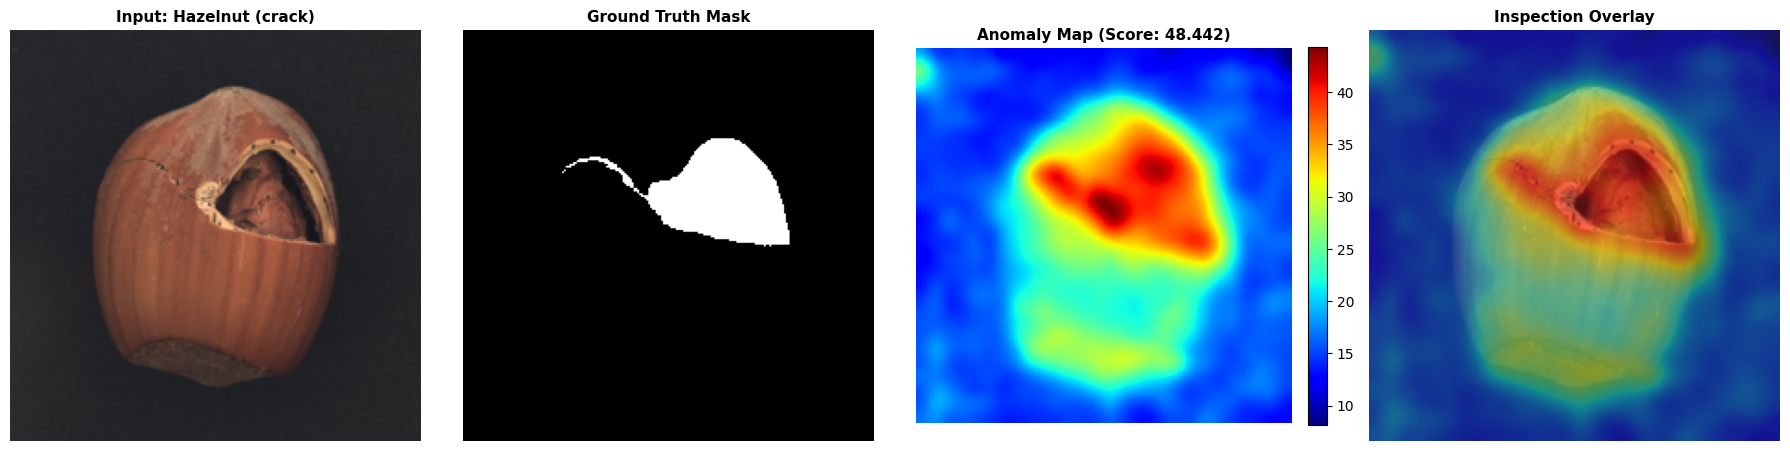

Saved comparison plot to /content/results/plots/hazelnut_sample_1.png


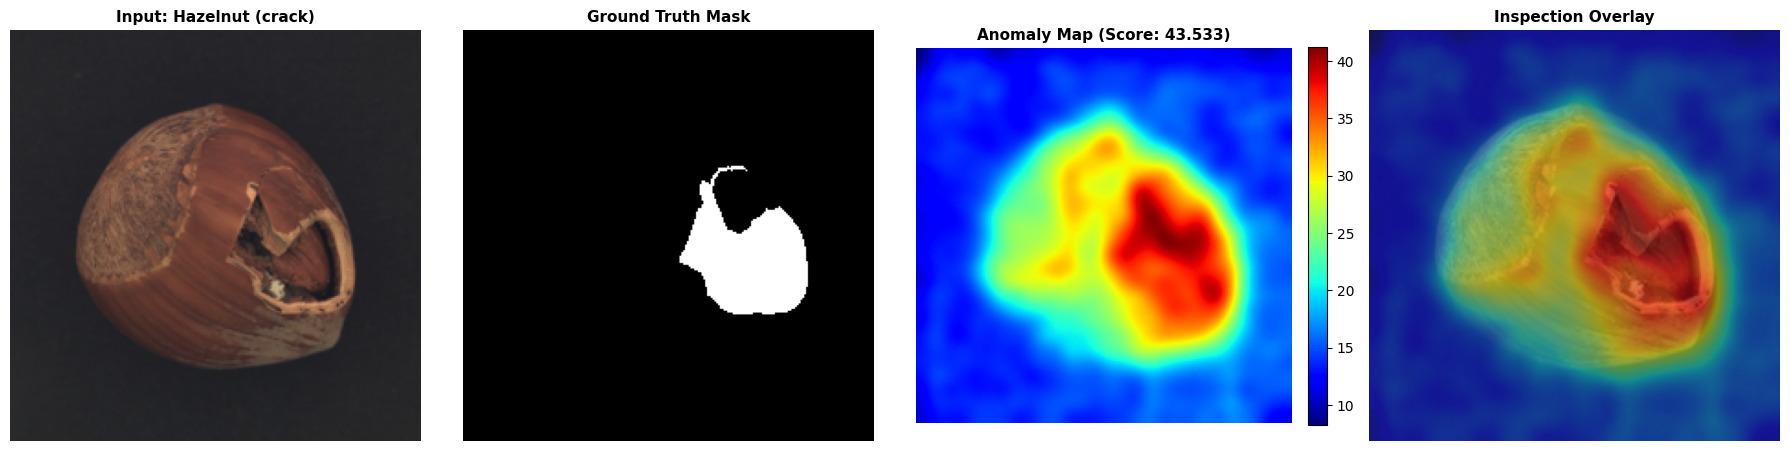

Saved comparison plot to /content/results/plots/hazelnut_sample_2.png


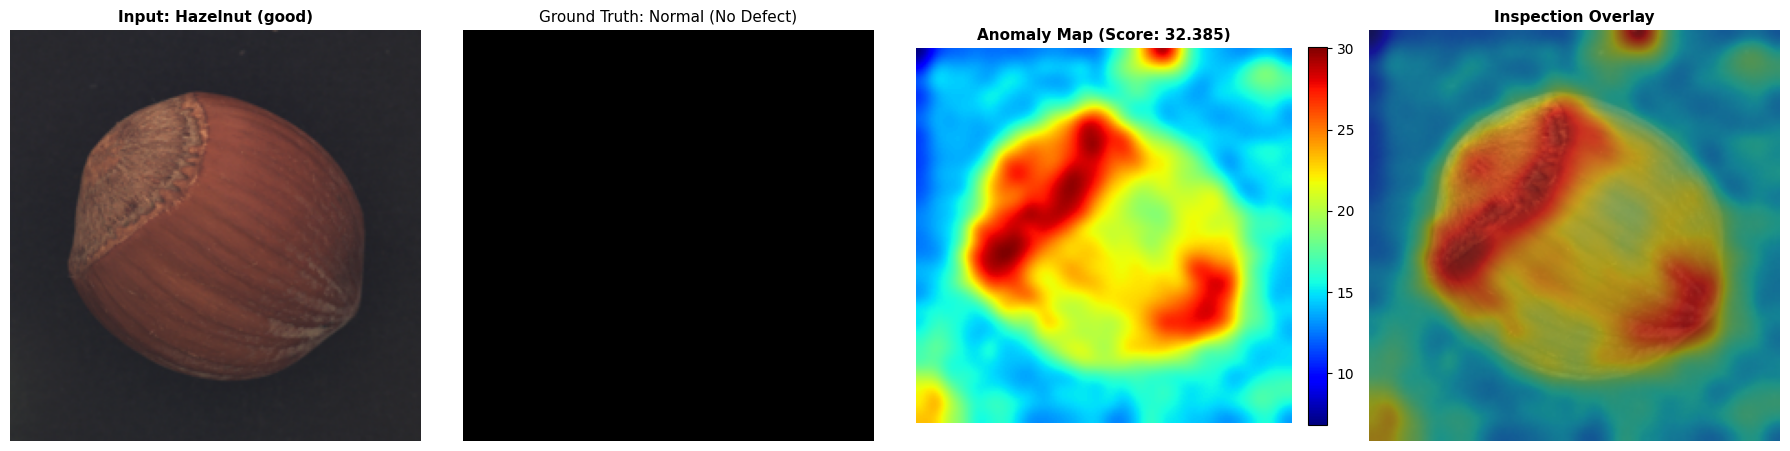

In [11]:
# CELL 9: Evaluate Cable & Hazelnut, Save Memory Bank Models (.pkl), & Generate Visualizations
import json
from src.anomaly_detection import MemoryBankAnomalyDetector, AnomalyInferenceEngine

ADDITIONAL_CATS = ['cable', 'hazelnut']
all_category_results = []

# Include bottle's already computed metrics if available
if 'metrics' in locals():
    all_category_results.append(metrics)
    models_dir = PROJECT_ROOT / 'models'
    models_dir.mkdir(parents=True, exist_ok=True)
    detector.category = 'bottle'
    detector.optimal_threshold = metrics['optimal_threshold']
    detector.save(models_dir / 'memory_bank_bottle.pkl')
    
    reports_dir = PROJECT_ROOT / 'reports'
    reports_dir.mkdir(parents=True, exist_ok=True)
    with open(reports_dir / 'bottle_metrics.json', 'w') as f:
        json.dump(metrics, f, indent=2)

for cat in ADDITIONAL_CATS:
    print(f"\n{'='*50}\n🚀 Benchmarking {cat.upper()}...\n{'='*50}")
    train_ds = MVTecDataset(metadata_df, transform=transforms, target_split='train', target_category=cat)
    test_ds = MVTecDataset(metadata_df, transform=transforms, target_split='test', target_category=cat)
    print(f"{cat}: {len(train_ds)} train normal images | {len(test_ds)} test images")
    
    # Extract train patches
    cat_train_patches = []
    for item in train_ds:
        p = extractor.extract_patch_features(item['image'], target_size=(28, 28))
        p_np = p.squeeze(0).permute(1, 2, 0).reshape(-1, p.shape[1]).cpu().numpy()
        cat_train_patches.append(p_np)
    
    cat_train_patches = np.vstack(cat_train_patches)
    cat_detector = MemoryBankAnomalyDetector(category=cat, n_neighbors=1, subsample_ratio=0.1)
    cat_detector.fit(cat_train_patches)
    
    # Score test images
    cat_y_true = []
    cat_y_scores = []
    cat_samples = []
    
    for item in test_ds:
        is_anomaly = item['is_anomaly']
        p = extractor.extract_patch_features(item['image'], target_size=(28, 28))
        p_np = p.squeeze(0).permute(1, 2, 0).reshape(-1, p.shape[1]).cpu().numpy()
        score, hmap = cat_detector.predict_image_and_map(p_np, spatial_grid=(28, 28), target_size=(224, 224))
        cat_y_true.append(is_anomaly)
        cat_y_scores.append(score)
        
        if (is_anomaly == 0 and len([s for s in cat_samples if s['is_anomaly'] == 0]) < 1) or \
           (is_anomaly == 1 and len([s for s in cat_samples if s['is_anomaly'] == 1]) < 2):
            raw_img = Image.open(item['image_path']).convert('RGB').resize((224, 224))
            mask_np = item['mask'].squeeze(0).cpu().numpy() if isinstance(item['mask'], torch.Tensor) else item['mask']
            cat_samples.append({
                'image': raw_img,
                'mask': mask_np,
                'heatmap': hmap,
                'score': score,
                'defect_type': item['defect_type'],
                'is_anomaly': is_anomaly
            })
    
    # Evaluation
    cat_metrics = evaluate_image_level(np.array(cat_y_true), np.array(cat_y_scores), category_name=cat)
    cat_detector.optimal_threshold = cat_metrics['optimal_threshold']
    all_category_results.append(cat_metrics)
    
    # Save model .pkl
    cat_detector.save(PROJECT_ROOT / 'models' / f"memory_bank_{cat}.pkl")
    
    # Save metrics json
    with open(PROJECT_ROOT / 'reports' / f"{cat}_metrics.json", 'w') as f:
        json.dump(cat_metrics, f, indent=2)
        
    # Plot ROC & PR
    plot_roc_pr_curves(
        np.array(cat_y_true),
        np.array(cat_y_scores),
        category_name=cat.title(),
        save_path=save_plot_dir / f"{cat}_roc_pr.png"
    )
    plt.show()
    
    # Plot samples
    for i, samp in enumerate(cat_samples):
        plot_anomaly_comparison(
            samp['image'],
            samp['mask'],
            samp['heatmap'],
            samp['score'],
            defect_type=samp['defect_type'],
            category=cat.title(),
            save_path=save_plot_dir / f"{cat}_sample_{i}.png"
        )
        plt.show()

In [12]:
# CELL 10: Multi-Category Anomaly Detection Summary Scoreboard
summary_df = pd.DataFrame(all_category_results)
summary_csv_path = PROJECT_ROOT / 'reports' / 'anomaly_detection_summary.csv'
summary_df.to_csv(summary_csv_path, index=False)

print("=" * 65)
print("🏆 DEFECTVISION: MULTI-CATEGORY ANOMALY DETECTION SCOREBOARD")
print("=" * 65)
display_cols = ['category', 'auroc', 'auprc', 'f1_score', 'precision', 'recall', 'optimal_threshold']
formatted_df = summary_df[display_cols].copy()
formatted_df['auroc'] = formatted_df['auroc'].apply(lambda x: f"{x*100:.2f}%")
formatted_df['auprc'] = formatted_df['auprc'].apply(lambda x: f"{x*100:.2f}%")
formatted_df['f1_score'] = formatted_df['f1_score'].apply(lambda x: f"{x:.4f}")
formatted_df['precision'] = formatted_df['precision'].apply(lambda x: f"{x*100:.2f}%")
formatted_df['recall'] = formatted_df['recall'].apply(lambda x: f"{x*100:.2f}%")
formatted_df['optimal_threshold'] = formatted_df['optimal_threshold'].apply(lambda x: f"{x:.4f}")
print(formatted_df.to_string(index=False))
print(f"\n✅ Summary metrics saved to: {summary_csv_path}")

🏆 DEFECTVISION: MULTI-CATEGORY ANOMALY DETECTION SCOREBOARD
category  auroc  auprc f1_score precision  recall optimal_threshold
  bottle 99.68% 99.90%   0.9756   100.00%  95.24%           35.8783
   cable 83.08% 88.28%   0.8377    80.81%  86.96%           39.5373
hazelnut 99.36% 99.58%   0.9929    98.59% 100.00%           39.5638

✅ Summary metrics saved to: /content/reports/anomaly_detection_summary.csv


In [13]:
# CELL 11: Smoke Test AnomalyInferenceEngine (Live Prediction Service)
test_engine = AnomalyInferenceEngine(category='bottle', models_dir=PROJECT_ROOT / 'models', extractor=extractor)
sample_bottle = test_dataset[0]['image_path']
res = test_engine.predict(sample_bottle)
print("✅ AnomalyInferenceEngine Smoke Test Succeeded!")
print(f"Sample: {sample_bottle}")
print(f"Score: {res['score']:.4f} | Threshold: {res['threshold']:.4f} | Defective: {res['is_defect']}")

✅ Loaded 'bottle' memory bank (16385 vectors, threshold=35.878257751464844)
✅ AnomalyInferenceEngine Smoke Test Succeeded!
Sample: /content/data/mvtec/bottle/test/broken_large/000.png
Score: 47.5395 | Threshold: 35.8783 | Defective: True


In [16]:
# CELL 12: Bundle & Download Tanya's Complete Deliverables
import shutil
bundle_zip = PROJECT_ROOT / 'tanya_anomaly_deliverables'
shutil.make_archive(str(bundle_zip), 'zip', PROJECT_ROOT, 'models')
print(f"📦 Packaged models into ZIP: {bundle_zip}.zip")

# 1. Save directly to your Google Drive (Guaranteed & Safe)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    import shutil
    shutil.copy(f"{bundle_zip}.zip", '/content/drive/MyDrive/tanya_anomaly_deliverables.zip')
    print("🎉 SUCCESS: Copied directly to your Google Drive! Check drive.google.com")
except Exception as e:
    print(f"Drive mount note: {e}")

# 2. Direct upload to bashupload & transfer.sh
print("Generating direct download links:")
!curl -s https://bashupload.com/ -T "{bundle_zip}.zip" || true
!curl -s --upload-file "{bundle_zip}.zip" https://transfer.sh/tanya_anomaly_deliverables.zip || true


Mounted at /content/drive
🎉 SUCCESS: Copied directly to your Google Drive! Check drive.google.com
Generating direct download links:
